# Single Neuron Models: Deep Dive
In this notebook, we dive deeper into the dynamics of single neurons, focusing on the Leaky Integrate-and-Fire (LIF) and Hodgkin-Huxley models.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import brian2 as b2
%matplotlib inline

## 1. The Leaky Integrate-and-Fire (LIF) Model
The LIF model is one of the simplest spiking neuron models. We will simulate it using Brian2.

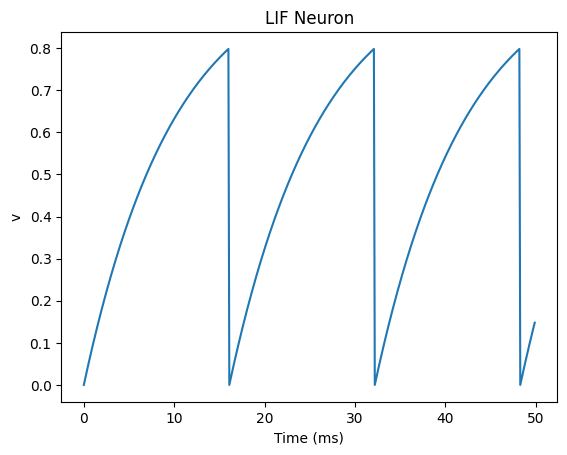

In [2]:
b2.start_scope()
tau = 10*b2.ms
eqs = '''
dv/dt = (1-v)/tau : 1
'''
G = b2.NeuronGroup(1, eqs, threshold='v>0.8', reset='v = 0', method='exact')
M = b2.StateMonitor(G, 'v', record=0)
b2.run(50*b2.ms)

plt.plot(M.t/b2.ms, M.v[0])
plt.xlabel('Time (ms)')
plt.ylabel('v')
plt.title('LIF Neuron')
plt.show()

## 2. The Hodgkin-Huxley Model
A more complex and biologically realistic model taking into account sodium and potassium ion channels.

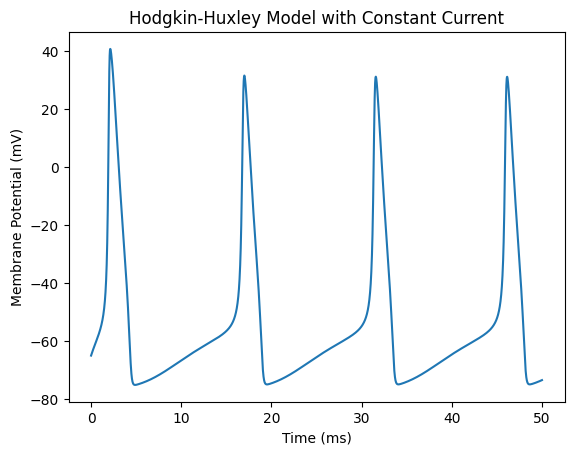

In [3]:
# Simplified pure Python implementation
def hodgkin_huxley(I_ext, time_span):
    # Constants
    C_m = 1.0 # uF/cm^2
    g_Na = 120.0 # mS/cm^2
    g_K = 36.0
    g_L = 0.3
    E_Na = 50.0 # mV
    E_K = -77.0
    E_L = -54.387

    # Time setup
    dt = 0.01
    t = np.arange(0, time_span, dt)
    
    # State variables
    V = np.zeros(len(t))
    m = np.zeros(len(t))
    h = np.zeros(len(t))
    n = np.zeros(len(t))
    
    # Initial conditions
    V[0] = -65.0
    m[0] = 0.05
    h[0] = 0.6
    n[0] = 0.32
    
    for i in range(1, len(t)):
        V_prev = V[i-1]
        
        # alpha and beta functions
        # adding small epsilon to prevent division by zero in case V exactly matches thresholds, 
        # though not typical with these initial conditions
        alpha_m = 0.1 * (V_prev + 40.0) / (1.0 - np.exp(-(V_prev + 40.0) / 10.0 + 1e-9))
        beta_m = 4.0 * np.exp(-(V_prev + 65.0) / 18.0)
        
        alpha_h = 0.07 * np.exp(-(V_prev + 65.0) / 20.0)
        beta_h = 1.0 / (1.0 + np.exp(-(V_prev + 35.0) / 10.0))
        
        alpha_n = 0.01 * (V_prev + 55.0) / (1.0 - np.exp(-(V_prev + 55.0) / 10.0 + 1e-9))
        beta_n = 0.125 * np.exp(-(V_prev + 65.0) / 80.0)
        
        # Update gating variables
        m[i] = m[i-1] + dt * (alpha_m * (1 - m[i-1]) - beta_m * m[i-1])
        h[i] = h[i-1] + dt * (alpha_h * (1 - h[i-1]) - beta_h * h[i-1])
        n[i] = n[i-1] + dt * (alpha_n * (1 - n[i-1]) - beta_n * n[i-1])
        
        # Currents
        I_Na = g_Na * m[i]**3 * h[i] * (V_prev - E_Na)
        I_K = g_K * n[i]**4 * (V_prev - E_K)
        I_L = g_L * (V_prev - E_L)
        
        # Update membrane potential
        V[i] = V[i-1] + dt * (I_ext - I_Na - I_K - I_L) / C_m
        
    return t, V

t, V = hodgkin_huxley(10, 50)
plt.plot(t, V)
plt.xlabel('Time (ms)')
plt.ylabel('Membrane Potential (mV)')
plt.title('Hodgkin-Huxley Model with Constant Current')
plt.show()